In [2]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

In [3]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        logical_gpus = tf.config.list_logical_devices('GPU')
        print(len(gpus), "Physical GPUs,", len(logical_gpus), "Logical GPUs")
    except RuntimeError as e:
        print(e)
     

1 Physical GPUs, 1 Logical GPUs


I0000 00:00:1795204439.611233     654 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [4]:
def plot_learning_curve(history):
    # Graficar exactitud
    plt.figure()
    plt.plot(history.history['accuracy'], label='Training accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation accuracy')
    plt.title('accuracy Curves')
    plt.legend()
    plt.show()

    # Graficar pérdida
    plt.figure()
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Loss Curves')
    plt.legend()
    plt.show()

In [5]:
(X_train, y_train), (X_test_full, y_test_full) = tf.keras.datasets.fashion_mnist.load_data()

In [6]:
X_test, X_val, y_test, y_val= train_test_split(
    X_test_full, y_test_full, test_size=0.50, random_state=42
)

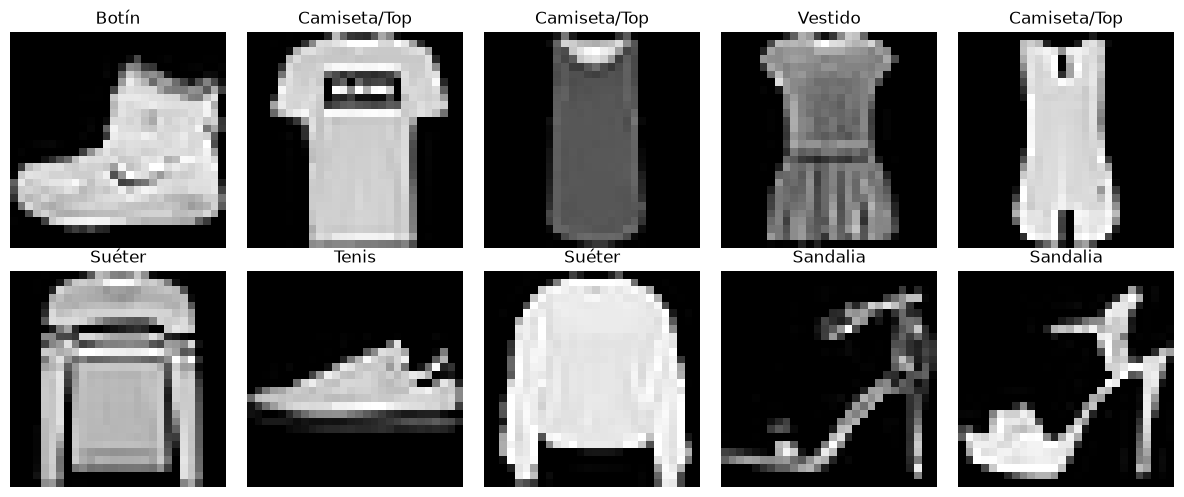

In [7]:
class_names = [
    "Camiseta/Top",  # 0: T-shirt/top
    "Pantalón",      # 1: Trouser
    "Suéter",        # 2: Pullover
    "Vestido",       # 3: Dress
    "Abrigo",        # 4: Coat
    "Sandalia",      # 5: Sandal
    "Camisa",        # 6: Shirt
    "Tenis",         # 7: Sneaker
    "Bolso",         # 8: Bag
    "Botín"          # 9: Ankle boot
]

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.tight_layout()
plt.show()

In [8]:
X_train.shape, X_test.shape, X_val.shape

((60000, 28, 28), (5000, 28, 28), (5000, 28, 28))

In [9]:
X_train_mlp = X_train / 255.0
X_test_mlp = X_test / 255.0
X_val_mlp = X_val / 255.0

In [10]:
X_train_mlp.shape

(60000, 28, 28)

# Red con pocas capas


In [40]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_mlp.shape[1], X_train_mlp.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [41]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           258 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 100,768 (393.62 KB)

 Trainable params: 100,768 (393.62 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
history = model.fit(
    X_train_mlp,
    y_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_val_mlp, y_val)
)

Epoch 1/50


I0000 00:00:1795205867.991593   15137 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_20', 12 bytes spill stores, 12 bytes spill loads



1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.6920 - loss: 0.9200 - val_accuracy: 0.7716 - val_loss: 0.7202
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7995 - loss: 0.6279 - val_accuracy: 0.7944 - val_loss: 0.6264
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8277 - loss: 0.5365 - val_accuracy: 0.8128 - val_loss: 0.5716
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8436 - loss: 0.4831 - val_accuracy: 0.8284 - val_loss: 0.5334
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8539 - loss: 0.4468 - val_accuracy: 0.8350 - val_loss: 0.5104
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8619 - loss: 0.4192 - val_accuracy: 0.8464 - val_loss: 0.4883
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8676 - loss: 0.3963 - val_accuracy: 0.8472 - val_loss: 0.4757
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8739 - loss: 0.3770 - val_accurac

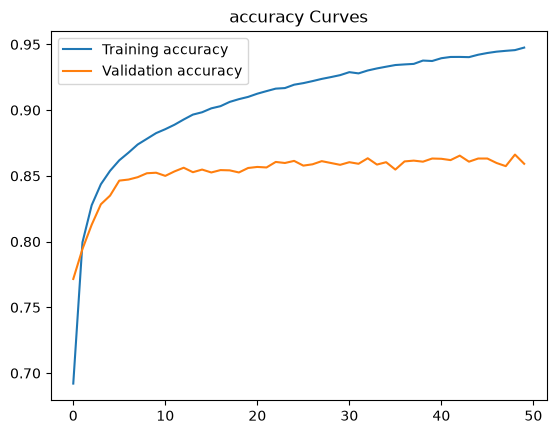

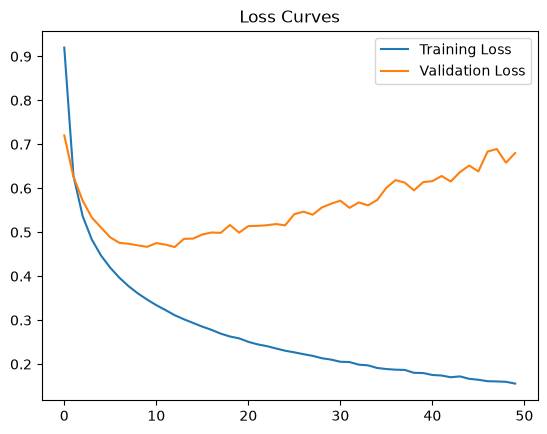

In [43]:
plot_learning_curve(history)

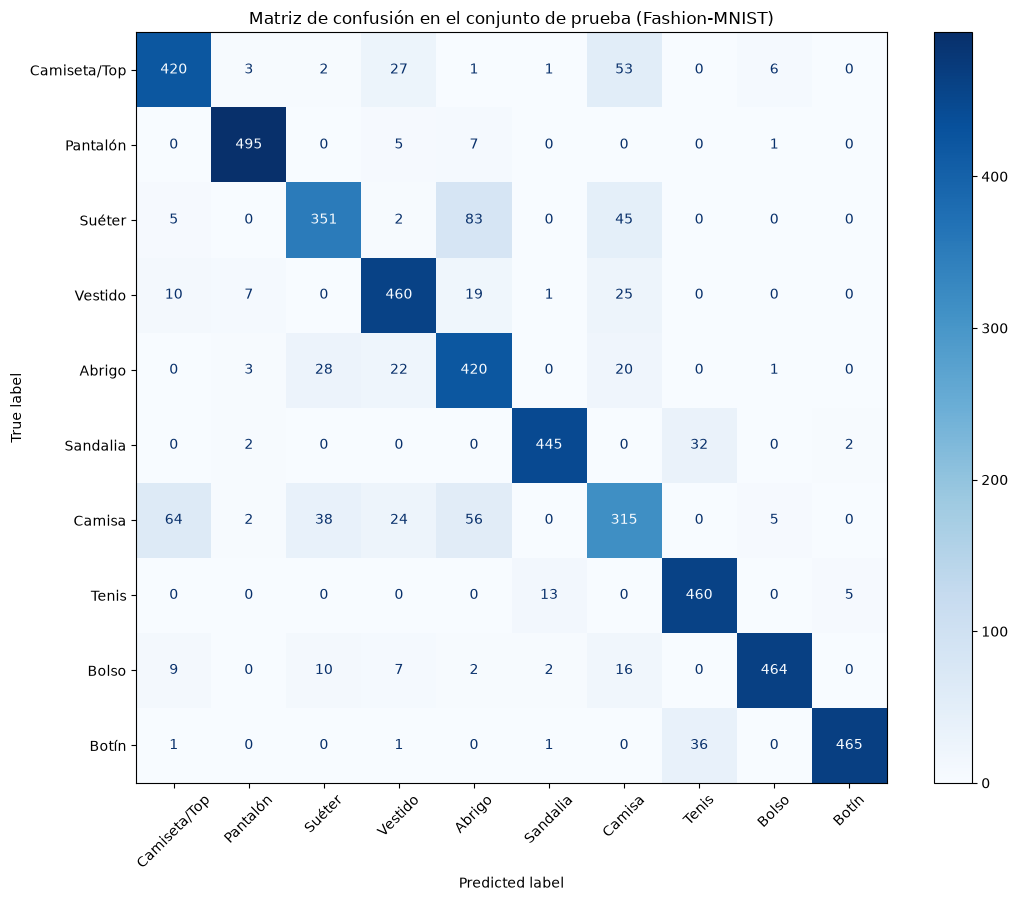

In [44]:
probabilidades = model.predict(X_test_mlp, verbose=0)

# Para multiclase, tomamos el índice con la probabilidad más alta
y_pred = np.argmax(probabilidades, axis=1)

# Graficar la matriz de confusión
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,  # Evita que los nombres de las prendas se encimen
    ax=ax,
)
plt.title("Matriz de confusión en el conjunto de prueba (Fashion-MNIST)")
plt.grid(False)
plt.tight_layout()
plt.show()

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step


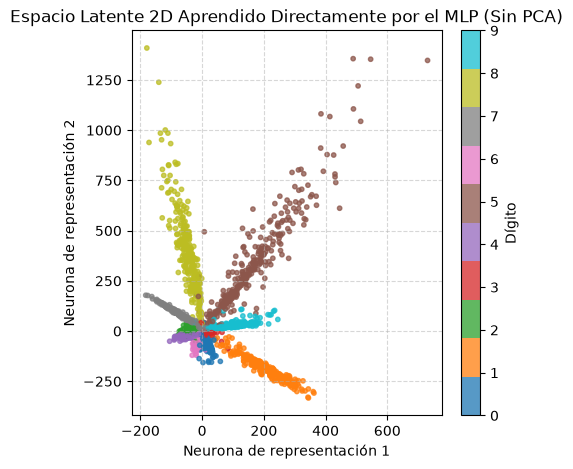

In [17]:
extractor = tf.keras.Model(
    inputs = model.inputs,
    outputs = model.get_layer("rep_2d").output
)

n = 3000
x_visual = X_val_mlp[:n]
y_visual = y_val[:n]

puntos2d = extractor.predict(x_visual)

plt.figure(figsize=(5,5))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_visual,
    cmap="tab10",
    s=10,
    alpha=0.75,
)
plt.title("Espacio Latente 2D Aprendido Directamente por el MLP (Sin PCA)")
plt.xlabel("Neurona de representación 1")
plt.ylabel("Neurona de representación 2")
plt.colorbar(scatter_plot, ticks=range(10), label="Dígito")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()
     

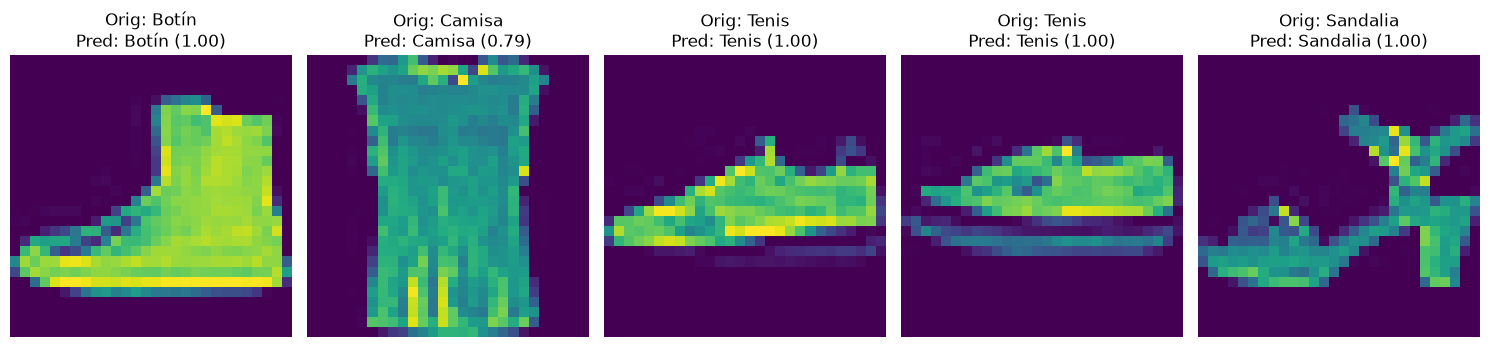

In [18]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = X_test_mlp[num_images:num_images+5]
original_labels = y_test[num_images:num_images+5]

# Realizar predicciones para originales y desplazadas
preds_original = model.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [19]:
model.predict(X_test_mlp[27].reshape(1,28,28), verbose=0)

array([[5.3393222e-05, 1.3835338e-10, 4.3285443e-03, 3.5828412e-10,
        5.7123005e-01, 6.3998213e-22, 4.2438799e-01, 8.8944253e-15,
        1.1725372e-19, 1.0726985e-18]], dtype=float32)

Predicción: Abrigo (57.12%)
Clase real: Abrigo


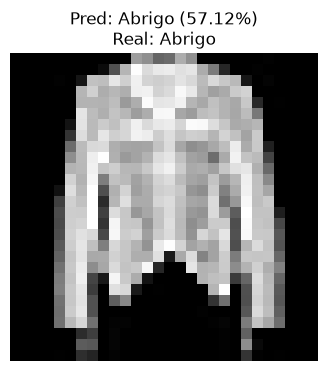

In [20]:
#Hecho con ayuda de IA.
idx = 27  # Índice del elemento en x_test que quieres evaluar

# 1. Realizar la predicción (forma (1, 10) con las probabilidades de cada clase)
probs = model.predict(X_test_mlp[idx].reshape(1, 28, 28), verbose=0)[0]

# 2. Obtener índice, nombre de la clase y probabilidad
clase_idx = np.argmax(probs)
nombre_clase = class_names[clase_idx]
probabilidad = probs[clase_idx] * 100

print(f"Predicción: {nombre_clase} ({probabilidad:.2f}%)")
print(f"Clase real: {class_names[y_test[idx]]}")

# 3. Visualizar la imagen con ambos resultados en el título
plt.figure(figsize=(4, 4))
plt.imshow(X_test_mlp[idx].squeeze(), cmap="gray")
plt.title(f"Pred: {nombre_clase} ({probabilidad:.2f}%)\nReal: {class_names[y_test[idx]]}")
plt.axis("off")
plt.show()

# Red convolucional

In [21]:
model_conv = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_mlp.shape[1], X_train_mlp.shape[2],1)),

    tf.keras.layers.Conv2D(32, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), padding = "same", activation = "relu"),
    tf.keras.layers.MaxPool2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model_conv.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [22]:
model_conv.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │           130 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 166,624 (650.88 KB)

 Trainable params: 166,624 (650.88 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
history2 = model_conv.fit(
    X_train_mlp,
    y_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_val_mlp, y_val)
)

Epoch 1/50


W0000 00:00:1795205034.126758    5745 cuda_timer.cc:88] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 4ms/step - accuracy: 0.6920 - loss: 0.8760 - val_accuracy: 0.8106 - val_loss: 0.5964
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8482 - loss: 0.4894 - val_accuracy: 0.8630 - val_loss: 0.4236
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8802 - loss: 0.3812 - val_accuracy: 0.8858 - val_loss: 0.3713
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8977 - loss: 0.3211 - val_accuracy: 0.8902 - val_loss: 0.3510
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9105 - loss: 0.2765 - val_accuracy: 0.8978 - val_loss: 0.3429
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9206 - loss: 0.2432 - val_accuracy: 0.9004 - val_loss: 0.3556
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9293 - loss: 0.2148 - val_accuracy: 0.9012 - val_loss: 0.3357
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9369 - loss: 0.1907 - val_accura

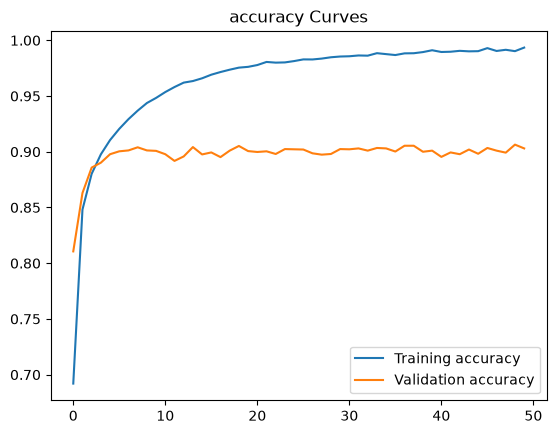

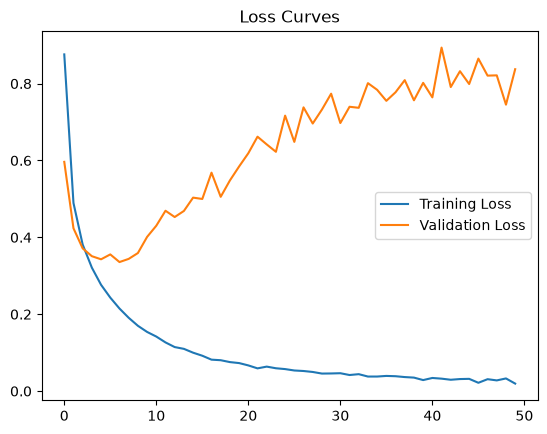

In [24]:
plot_learning_curve(history2)

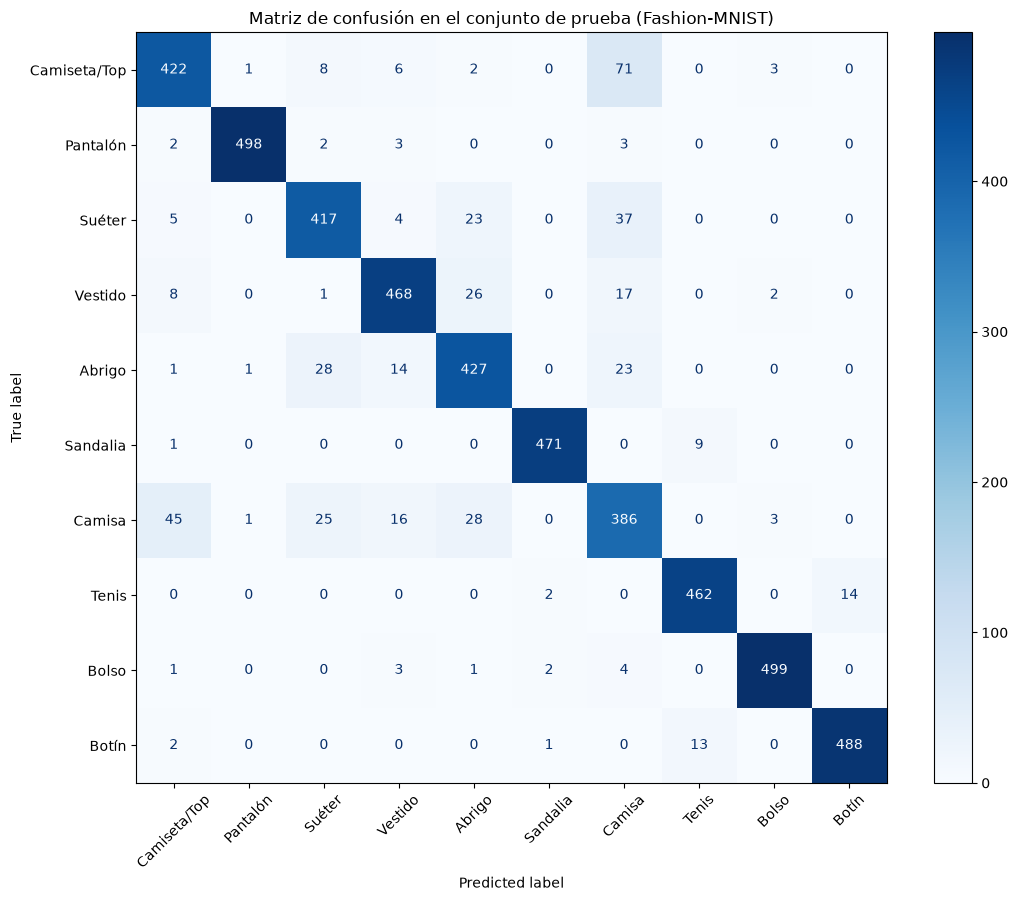

In [25]:
probabilidades = model_conv.predict(X_test_mlp, verbose=0)

# Para multiclase, tomamos el índice con la probabilidad más alta
y_pred = np.argmax(probabilidades, axis=1)

# Graficar la matriz de confusión
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,  # Evita que los nombres de las prendas se encimen
    ax=ax,
)
plt.title("Matriz de confusión en el conjunto de prueba (Fashion-MNIST)")
plt.grid(False)
plt.tight_layout()
plt.show()

89/94 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

I0000 00:00:1795205462.218684   10160 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 4 bytes spill stores, 4 bytes spill loads



94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step


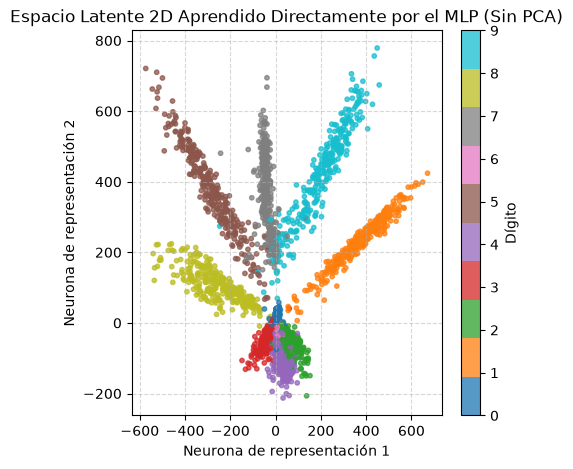

In [26]:
extractor = tf.keras.Model(
    inputs = model_conv.inputs,
    outputs = model_conv.get_layer("rep_2d").output
)

n = 3000
x_visual = X_val_mlp[:n]
y_visual = y_val[:n]

puntos2d = extractor.predict(x_visual)

plt.figure(figsize=(5,5))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_visual,
    cmap="tab10",
    s=10,
    alpha=0.75,
)
plt.title("Espacio Latente 2D Aprendido Directamente por el MLP (Sin PCA)")
plt.xlabel("Neurona de representación 1")
plt.ylabel("Neurona de representación 2")
plt.colorbar(scatter_plot, ticks=range(10), label="Dígito")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

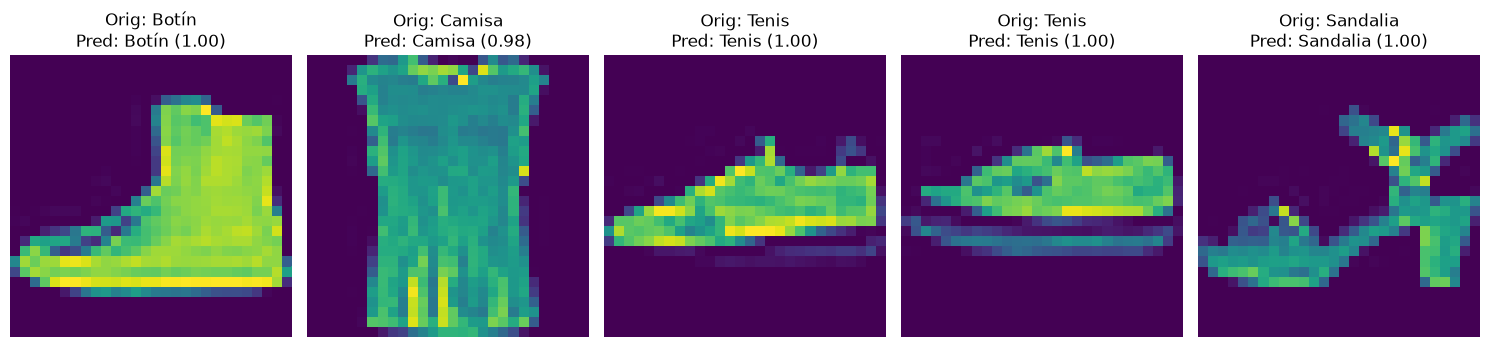

In [27]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = X_test_mlp[num_images:num_images+5]
original_labels = y_test[num_images:num_images+5]

# Realizar predicciones para originales y desplazadas
preds_original = model_conv.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [28]:
model_conv.predict(X_test_mlp[97].reshape(1,28,28), verbose=0)

array([[3.6752043e-38, 1.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 0.0000000e+00,
        0.0000000e+00, 1.2631978e-15]], dtype=float32)

Predicción: Pantalón (100.00%)
Clase real: Pantalón


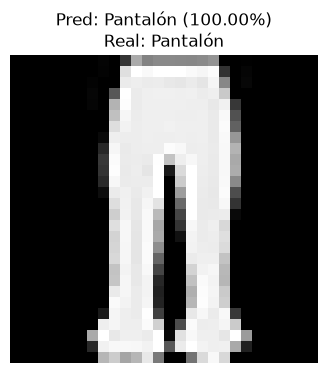

In [29]:
#Hecho con ayuda de IA.
idx = 97  # Índice del elemento en x_test que quieres evaluar

# 1. Realizar la predicción (forma (1, 10) con las probabilidades de cada clase)
probs = model_conv.predict(X_test_mlp[idx].reshape(1, 28, 28), verbose=0)[0]

# 2. Obtener índice, nombre de la clase y probabilidad
clase_idx = np.argmax(probs)
nombre_clase = class_names[clase_idx]
probabilidad = probs[clase_idx] * 100

print(f"Predicción: {nombre_clase} ({probabilidad:.2f}%)")
print(f"Clase real: {class_names[y_test[idx]]}")

# 3. Visualizar la imagen con ambos resultados en el título
plt.figure(figsize=(4, 4))
plt.imshow(X_test_mlp[idx].squeeze(), cmap="gray")
plt.title(f"Pred: {nombre_clase} ({probabilidad:.2f}%)\nReal: {class_names[y_test[idx]]}")
plt.axis("off")
plt.show()

# Red con mas capas

In [30]:
model_2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_mlp.shape[1], X_train_mlp.shape[2])),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation = "relu"),
    tf.keras.layers.Dense(units = 64, activation = "relu"),
    tf.keras.layers.Dense(units = 32, activation = "relu"),
    tf.keras.layers.Dense(units = 16, activation = "relu"),
    tf.keras.layers.Dense(units = 2, activation = "linear", name = "rep_2d"),
    tf.keras.layers.Dense(units = 10, activation = "softmax")
])


model_2.compile(
    optimizer = "adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [31]:
model_2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rep_2d (Dense)                  │ (None, 2)              │            34 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,408 (435.19 KB)

 Trainable params: 111,408 (435.19 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
history3 = model_2.fit(
    X_train_mlp,
    y_train,
    epochs = 50,
    batch_size = 32,
    validation_data = (X_val_mlp, y_val)
)

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6471 - loss: 1.0415 - val_accuracy: 0.7572 - val_loss: 0.7773
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7950 - loss: 0.6857 - val_accuracy: 0.7994 - val_loss: 0.6673
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8222 - loss: 0.5975 - val_accuracy: 0.8244 - val_loss: 0.6278
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8375 - loss: 0.5447 - val_accuracy: 0.8344 - val_loss: 0.5952
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8493 - loss: 0.5029 - val_accuracy: 0.8404 - val_loss: 0.6034
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8570 - loss: 0.4801 - val_accuracy: 0.8484 - val_loss: 0.5744
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8654 - loss: 0.4462 - val_accuracy: 0.8546 - val_loss: 0.5765
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.8668 - loss: 0.4343 - 

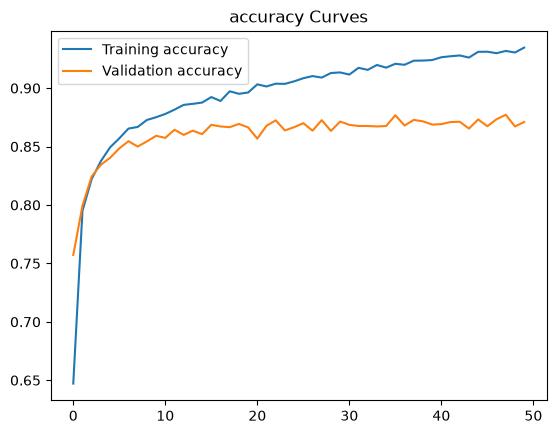

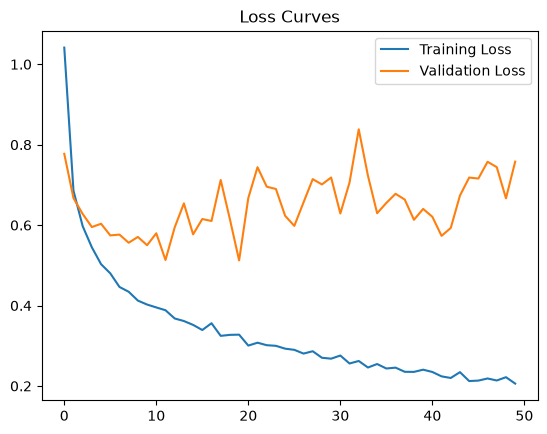

In [33]:
plot_learning_curve(history3)

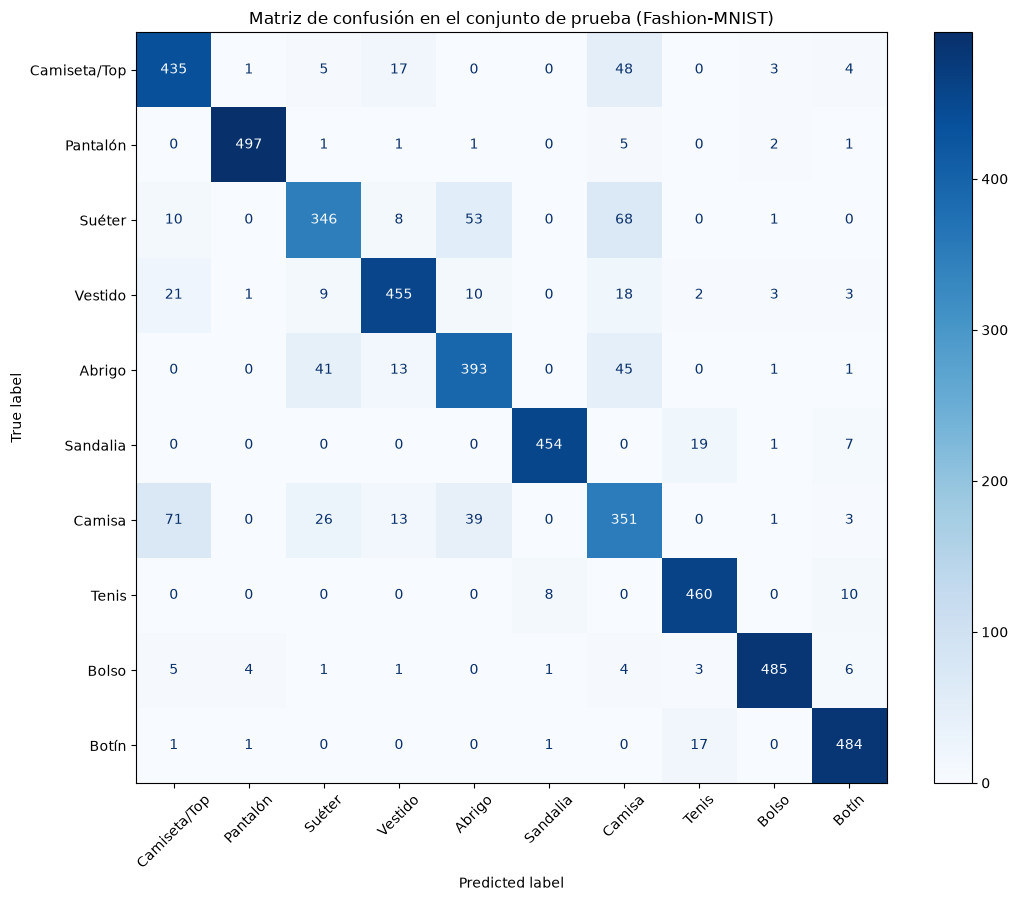

In [34]:
probabilidades = model_2.predict(X_test_mlp, verbose=0)

# Para multiclase, tomamos el índice con la probabilidad más alta
y_pred = np.argmax(probabilidades, axis=1)

# Graficar la matriz de confusión
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45,  # Evita que los nombres de las prendas se encimen
    ax=ax,
)
plt.title("Matriz de confusión en el conjunto de prueba (Fashion-MNIST)")
plt.grid(False)
plt.tight_layout()
plt.show()

94/94 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step


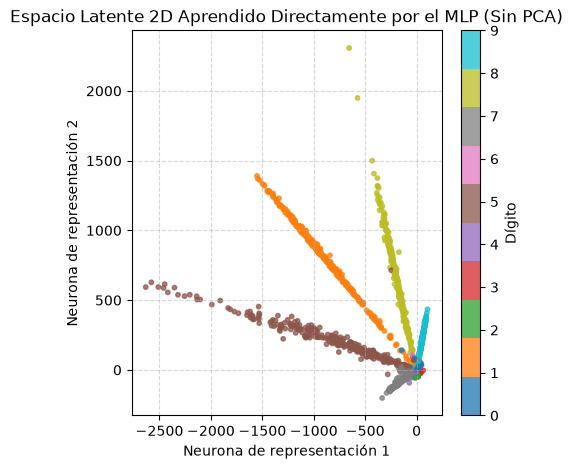

In [35]:
extractor = tf.keras.Model(
    inputs = model_2.inputs,
    outputs = model_2.get_layer("rep_2d").output
)

n = 3000
x_visual = X_val_mlp[:n]
y_visual = y_val[:n]

puntos2d = extractor.predict(x_visual)

plt.figure(figsize=(5,5))
scatter_plot = plt.scatter(
    puntos2d[:, 0],
    puntos2d[:, 1],
    c=y_visual,
    cmap="tab10",
    s=10,
    alpha=0.75,
)
plt.title("Espacio Latente 2D Aprendido Directamente por el MLP (Sin PCA)")
plt.xlabel("Neurona de representación 1")
plt.ylabel("Neurona de representación 2")
plt.colorbar(scatter_plot, ticks=range(10), label="Dígito")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

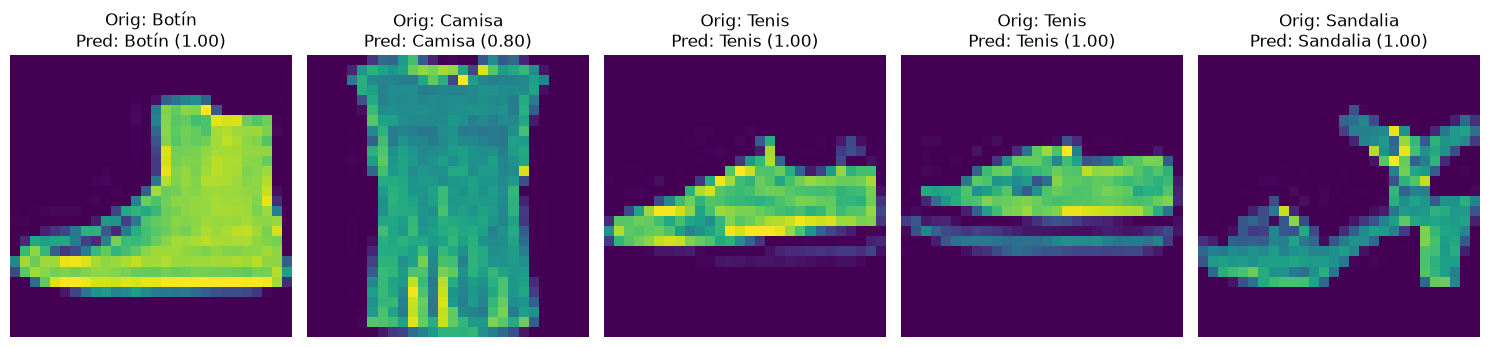

In [36]:
# Seleccionar 5 imágenes de prueba
num_images = 5
original_images = X_test_mlp[num_images:num_images+5]
original_labels = y_test[num_images:num_images+5]

# Realizar predicciones para originales y desplazadas
preds_original = model_2.predict(original_images, verbose=0)

# Graficar los resultados de la comparación
fig, axes = plt.subplots(1, num_images, figsize=(15, 6))

for i in range(num_images):
    # Mostrar imagen original
    axes[i].imshow(original_images[i])
    pred_orig_label = np.argmax(preds_original[i])
    pred_orig_conf = preds_original[i][pred_orig_label]
    axes[i].set_title(f"Orig: {class_names[original_labels[i]]}\nPred: {class_names[pred_orig_label]} ({pred_orig_conf:.2f})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [37]:
model_2.predict(X_test_mlp[49].reshape(1,28,28), verbose=0)

array([[0.0000000e+00, 3.4403838e-17, 0.0000000e+00, 0.0000000e+00,
        8.4933574e-18, 1.9218383e-07, 1.2611686e-44, 9.9999976e-01,
        1.3792840e-28, 9.9137046e-38]], dtype=float32)

Predicción: Sandalia (100.00%)
Clase real: Sandalia


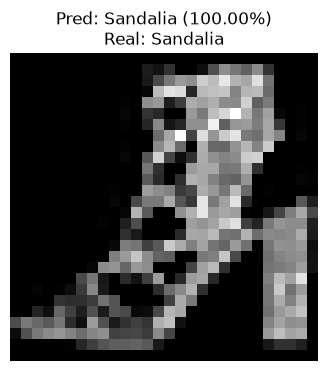

In [39]:
#Hecho con ayuda de IA.
idx = 50  # Índice del elemento en x_test que quieres evaluar

# 1. Realizar la predicción (forma (1, 10) con las probabilidades de cada clase)
probs = model_2.predict(X_test_mlp[idx].reshape(1, 28, 28), verbose=0)[0]

# 2. Obtener índice, nombre de la clase y probabilidad
clase_idx = np.argmax(probs)
nombre_clase = class_names[clase_idx]
probabilidad = probs[clase_idx] * 100

print(f"Predicción: {nombre_clase} ({probabilidad:.2f}%)")
print(f"Clase real: {class_names[y_test[idx]]}")

# 3. Visualizar la imagen con ambos resultados en el título
plt.figure(figsize=(4, 4))
plt.imshow(X_test_mlp[idx].squeeze(), cmap="gray")
plt.title(f"Pred: {nombre_clase} ({probabilidad:.2f}%)\nReal: {class_names[y_test[idx]]}")
plt.axis("off")
plt.show()